In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score, classification_report

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

In [ ]:
# 1. Carrega o conjunto de dados nativo do Scikit-Learn
iris = load_iris()

In [ ]:
# 2. Converte a matriz de dados em DataFrame Pandas
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)

# 3. Adiciona a coluna do alvo (target) mapeando o nome das espécies
df['species'] = iris.target_names[iris.target]

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [ ]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [ ]:
df.shape

(150, 5)

In [ ]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,149.000000,149.000000,149.000000,149.000000
mean,5.843624,3.059732,3.748993,1.194631
std,0.830851,0.436342,1.767791,0.762622
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.300000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [ ]:
df.isnull().sum()

,0
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0
species,0


In [ ]:
print(df.duplicated().sum())

1


In [ ]:
df[df.duplicated()]

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
142,5.8,2.7,5.1,1.9,virginica


In [ ]:
df = df.drop_duplicates()

In [ ]:
df[df.duplicated()]

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species


In [ ]:
df['species'].value_counts()

,count
species,
setosa,50
versicolor,50
virginica,49


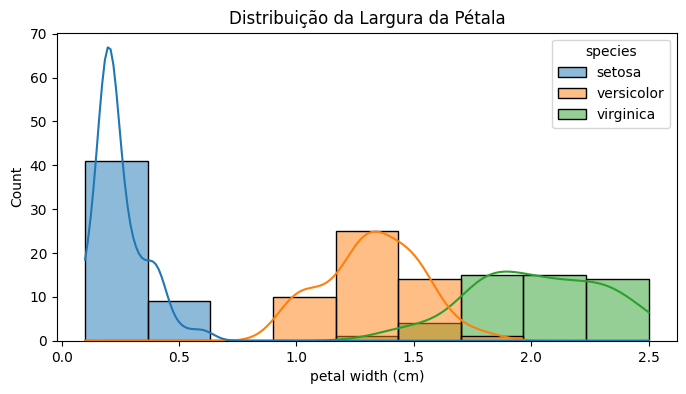

In [ ]:
# Histograma da largura da pétala por espécie
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="petal width (cm)", hue="species", kde=True)
plt.title("Distribuição da Largura da Pétala")
plt.show()

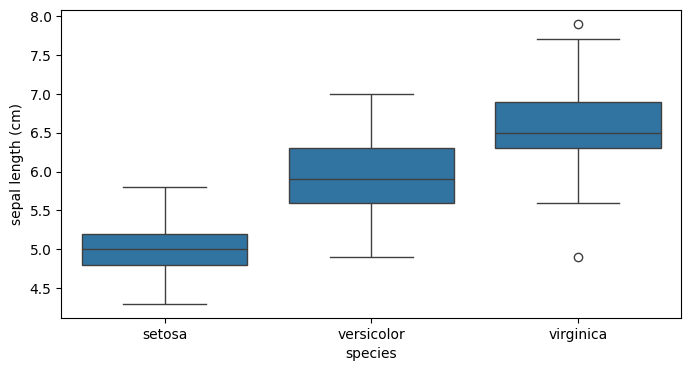

In [ ]:
# Boxplot do comprimento da sépala por espécie
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x="species", y="sepal length (cm)")
plt.show()

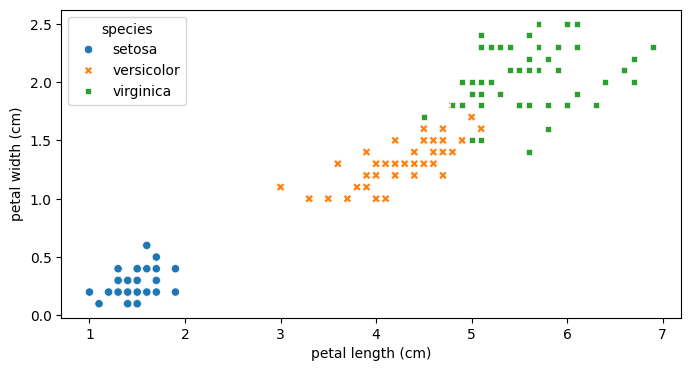

In [ ]:
# Dispersão entre comprimento e largura da pétala
plt.figure(figsize=(8, 4))
sns.scatterplot(data=df, x="petal length (cm)",
                y="petal width (cm)",
                hue="species", style="species")
plt.show()


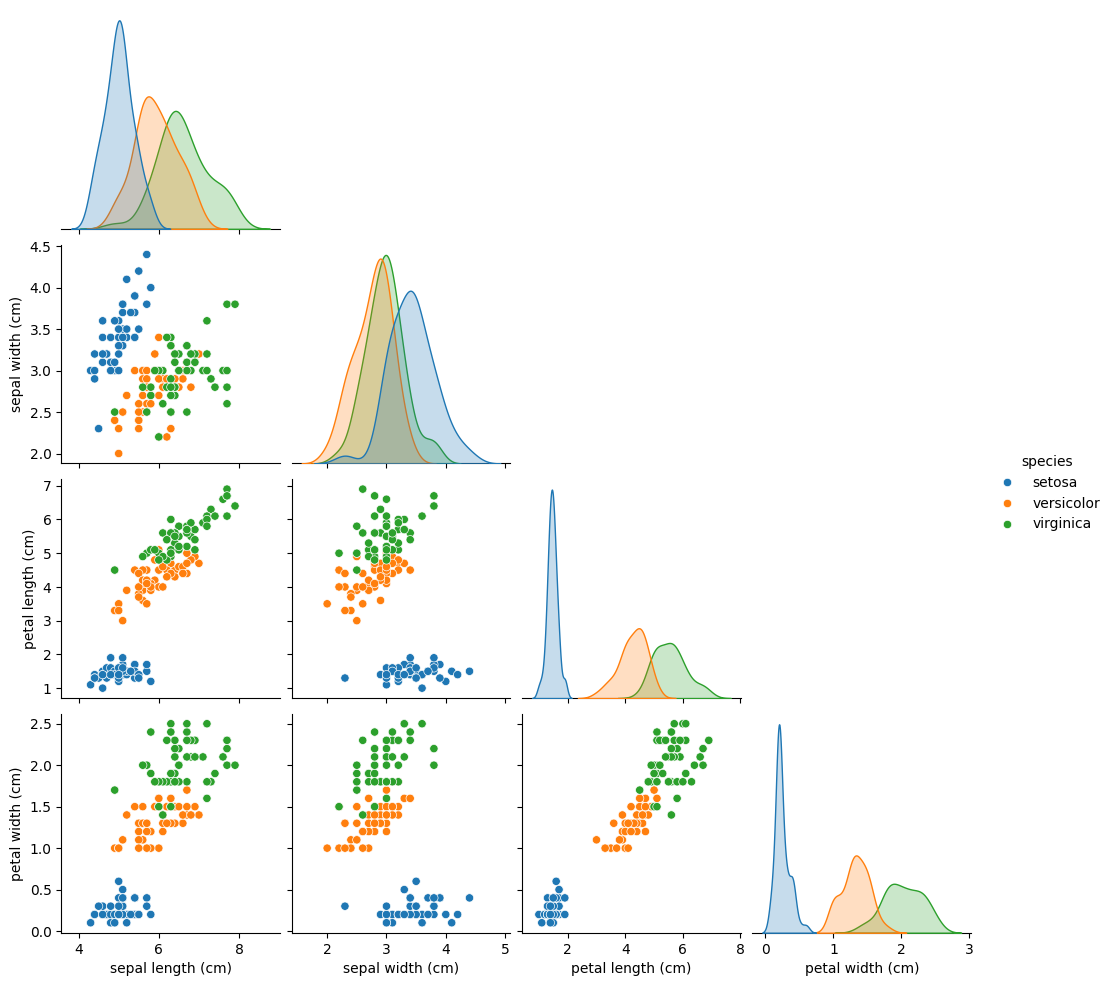

In [ ]:
# Plota cruzamentos de todas as features numéricas
sns.pairplot(df, hue="species", corner=True)
plt.show()

In [ ]:
X = df.drop('species', axis=1)

y = df['species']

In [ ]:
print(X.shape)

print(y.shape)

(149, 4)
(149,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
# Modelo 1
tree_model = DecisionTreeClassifier(max_depth=3)
tree_model.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=3)

In [ ]:
tree_predict = tree_model.predict(X_test)

In [ ]:
tree_result = accuracy_score(y_test, tree_predict)

[Text(0.375, 0.875, 'petal length (cm) <= 2.45\ngini = 0.667\nsamples = 119\nvalue = [40, 40, 39]'),
 Text(0.25, 0.625, 'gini = 0.0\nsamples = 40\nvalue = [40, 0, 0]'),
 Text(0.3125, 0.75, 'True  '),
 Text(0.5, 0.625, 'petal width (cm) <= 1.65\ngini = 0.5\nsamples = 79\nvalue = [0, 40, 39]'),
 Text(0.4375, 0.75, '  False'),
 Text(0.25, 0.375, 'petal length (cm) <= 4.95\ngini = 0.133\nsamples = 42\nvalue = [0, 39, 3]'),
 Text(0.125, 0.125, 'gini = 0.0\nsamples = 38\nvalue = [0, 38, 0]'),
 Text(0.375, 0.125, 'gini = 0.375\nsamples = 4\nvalue = [0, 1, 3]'),
 Text(0.75, 0.375, 'petal length (cm) <= 4.85\ngini = 0.053\nsamples = 37\nvalue = [0, 1, 36]'),
 Text(0.625, 0.125, 'gini = 0.444\nsamples = 3\nvalue = [0, 1, 2]'),
 Text(0.875, 0.125, 'gini = 0.0\nsamples = 34\nvalue = [0, 0, 34]')]

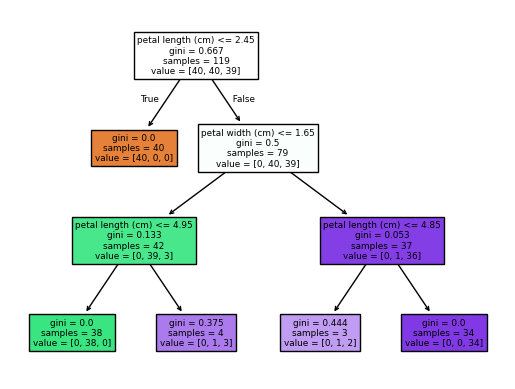

In [ ]:
plot_tree(tree_model, feature_names=X.columns, filled=True)

In [ ]:
log_model = LogisticRegression(max_iter=200, random_state=42)
log_model.fit(X_train, y_train)

LogisticRegression(max_iter=200, random_state=42)

In [ ]:
log_predict = log_model.predict(X_test)

In [ ]:
log_result = accuracy_score(y_test, log_predict)

In [ ]:
print(f"Acurácia Árvore: {tree_result * 100:.2f}%")
print(f"Acurácia Reg. Logística: {log_result * 100:.2f}%")


Acurácia Árvore: 96.67%
Acurácia Reg. Logística: 96.67%


In [ ]:
nova_flor = [[5.1, 3.5, 1.4, 0.2]] # Comprimento/Largura
especie_prevista = tree_model.predict(nova_flor)
print("Espécie Prevista:", especie_prevista[0])

log_especie_prevista = log_model.predict(nova_flor)
print("Espécie Prevista:", log_especie_prevista[0])

Espécie Prevista: setosa
Espécie Prevista: setosa


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


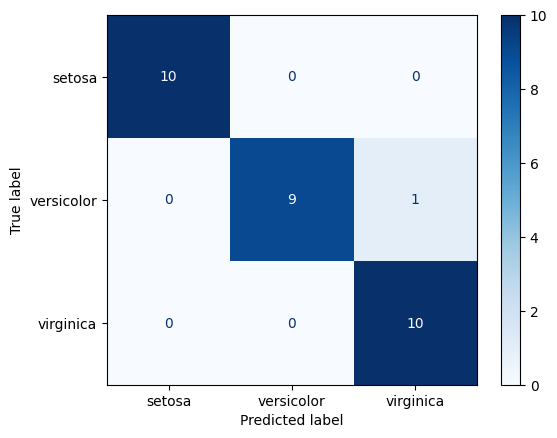

In [ ]:
# Plotando a Matriz de Confusão
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Matriz de Confusão para a Árvore de Decisão
cm = confusion_matrix(y_test, tree_predict)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=iris.target_names)
disp.plot(cmap="Blues")
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, tree_predict))


              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [ ]:
print(classification_report(y_test, log_predict))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

